# Проект. Исследование стартапов

## Введение

## Цели и задачи

### Цель: провести исследовательский анализ данных компаний для вывления закономерности  финансирования стартапов 

### Задачи:
1. Загрузить данные и познакомиться с их содержимым
2. Провести предобработку данных
3. Провести  исследовательский анализ данных
4. Сформулировать выводы и рекомендации

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_inv.....ip`. Внутри архива один файл — `cb_i...sv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
*...
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_...sv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* ...
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


### 1.1. Вывод общей информации


In [1]:
import pandas as pd
#Загружаем библиотеки для визуализации
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("https://cod...ip", sep=';', low_memory=False)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Датасет `cb_...sv` состоит из 54294 строк и 40 столбцов, которые содержат информацию о компаниях и состоявшемся финансировании.
После певичного анадиза данных можно сделать выводы:
- значения в столбцах соответствуют своему описанию
- в названии столбцов `market` и `funding_total_usd` присутсвуют лишние пробелы, необходимо првести к одному стилю
- в столбце `funding_total_usd` данные хранятся в типе object, необходимо привести к типу float
- столбцы `first_funding_at`,`mid_funding_at` и `last_funding_at` лучше привести к типу datetime
- пропуски содержатся во всех столбцах 

In [7]:
df_1=pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv")

In [8]:
df_1.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [9]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Датасет `cb_r...sv` состоит из 15 строк и 14 столбцов, которые содержат информацию  об объёмах возвратов по годам и типам финансирования в миллионах долларов
После первичного анализа можно сделать выводы:
- значения в столбцах соответсвуют описанию
- данные приведены к единому типу
- пропуски в значениях отсутствуют

### 1.2. Предобработка данных

Проверим названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле.

In [10]:
df=df.rename(columns={' market ':'market',
                      ' funding_total_usd ':'funding_total_usd'})


In [11]:
df['funding_total_usd']=df['funding_total_usd'].str.replace(',','')

In [12]:
df['funding_total_usd']=pd.to_numeric(df['funding_total_usd'],errors='coerce')
df['funding_total_usd'].dtype

dtype('float64')

In [13]:
df['first_funding_at'] = pd.to_datetime(df['first_funding_at'], errors='coerce')

In [14]:
df['first_funding_at']

0       2014-01-06
1       2014-05-15
2       2009-07-02
3       2013-11-21
4       2014-01-14
           ...    
54289          NaT
54290          NaT
54291          NaT
54292          NaT
54293          NaT
Name: first_funding_at, Length: 54294, dtype: datetime64[ns]

In [15]:
df['last_funding_at']=pd.to_datetime(df['last_funding_at'],errors='coerce')

In [16]:
df_1=df_1.set_index('year')


In [17]:
df['market'].nunique()

939

In [18]:
df['market']=df['market'].str.lower().str.strip()
df['market'].nunique()

439

После проверки столбца `market` выяснилось, что в нём находится 500 неявных дубликатов.

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [19]:
df.duplicated().sum()

4855

В датафрейме `df` 4855 полных дубликатов.

In [20]:
df=df.drop_duplicates()

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 49439 entries, 0 to 49438
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  49437 non-null  object        
 1   homepage_url          45989 non-null  object        
 2   category_list         45477 non-null  object        
 3   market                45477 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                48124 non-null  object        
 6   country_code          44165 non-null  object        
 7   state_code            30161 non-null  object        
 8   region                44165 non-null  object        
 9   city                  43322 non-null  object        
 10  funding_rounds        49438 non-null  float64       
 11  participants          30473 non-null  float64       
 12  founded_at            38554 non-null  object        
 13  founded_month   

Удалим пустые строки в столбце `funding_total_usd`

In [22]:
df=df.dropna(subset=['funding_total_usd']).copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 40907 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40906 non-null  object        
 1   homepage_url          38593 non-null  object        
 2   category_list         38404 non-null  object        
 3   market                38404 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                39802 non-null  object        
 6   country_code          37088 non-null  object        
 7   state_code            25619 non-null  object        
 8   region                37088 non-null  object        
 9   city                  36402 non-null  object        
 10  funding_rounds        40907 non-null  float64       
 11  participants          27331 non-null  float64       
 12  founded_at            32201 non-null  object        
 13  founded_month   

Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмем приблизительно середину интервала между этими двумя датами.


In [23]:
# Вычисляем середину интервала (в наносекундах, чтобы избежать проблем с timedelta)
mid_dates = df['first_funding_at'] + ((df['last_funding_at'] - df['first_funding_at']) / 2)

# Заполняем пропуски в mid_funding_at
df['mid_funding_at'] = df['mid_funding_at'].fillna(mid_dates)

,mid_funding_at,first_funding_at,last_funding_at
0,2014-01-06,2014-01-06,2014-01-06
1,2014-05-15,2014-05-15,2014-05-15
2,2009-07-02,2009-07-02,2009-07-02
3,2013-11-21,2013-11-21,2014-11-03
4,2014-01-14,2014-01-14,2014-01-14
...,...,...,...
49433,2014-12-01,2014-12-01,2014-12-01
49434,2014-12-01,2014-12-01,2014-12-01
49435,2014-12-02,2014-12-02,2014-12-02
49436,2014-12-02,2014-12-02,2014-12-02


In [24]:
df['mid_funding_at'].isna().sum()

1

In [25]:
df.isna().sum()/df.shape[0]

name                    0.000024
homepage_url            0.056567
category_list           0.061188
market                  0.061188
funding_total_usd       0.000000
status                  0.027012
country_code            0.093358
state_code              0.373726
region                  0.093358
city                    0.110128
funding_rounds          0.000000
participants            0.331875
founded_at              0.212824
founded_month           0.214438
founded_quarter         0.214438
founded_year            0.212824
first_funding_at        0.000049
mid_funding_at          0.000024
last_funding_at         0.000000
seed                    0.000000
venture                 0.000000
equity_crowdfunding     0.000000
undisclosed             0.000000
convertible_note        0.000000
debt_financing          0.000000
angel                   0.000000
grant                   0.000000
private_equity          0.000000
post_ipo_equity         0.000000
post_ipo_debt           0.000000
secondary_

Самое большео значение пропущенных данных в столбце `state_code` - 37%. Заполнять его мы не будем. Во всех остальных столбцах не очень большой процент пропусков.

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 40907 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40906 non-null  object        
 1   homepage_url          38593 non-null  object        
 2   category_list         38404 non-null  object        
 3   market                38404 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                39802 non-null  object        
 6   country_code          37088 non-null  object        
 7   state_code            25619 non-null  object        
 8   region                37088 non-null  object        
 9   city                  36402 non-null  object        
 10  funding_rounds        40907 non-null  float64       
 11  participants          27331 non-null  float64       
 12  founded_at            32201 non-null  object        
 13  founded_month   

После очистки данных у нас осталось 40907 строк и 44 столбца.

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.



 Создадим столбец, который будет отображать срок финансирования

In [27]:
df['funding_at']=(df['last_funding_at'].dt.year)-(df['first_funding_at'].dt.year)<=1
# Если срок финансирования меньше года, столбце отобразит True

In [28]:
#Разделим все компании на три группы 
def fin_group(row): 
    if row['funding_rounds']==1:
        return 'Единичное финансирование'
    elif row['funding_at']==True:
        return 'Срок финансирования до года'
    else:
        return'Срок финансирования больше года'
df['group']=df.apply(fin_group,axis=1)

In [29]:
df['group'].value_counts(normalize=True)

Единичное финансирование           0.589459
Срок финансирования больше года    0.238272
Срок финансирования до года        0.172269
Name: group, dtype: float64

Визуализируем, какой процент от общего числа компаний относится к кадой группе

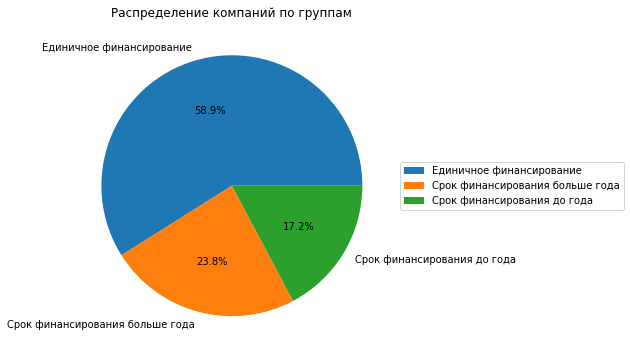

In [30]:
df['group'].value_counts(normalize=True).plot(kind='pie',
                                              figsize=(10,6), 
                                              legend=True, 
                                              rot=0,
                                              autopct='%.1f%%',
                                              title='Распределение компаний по группам',
                                              ylabel='')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

Самый большой процент компаний с "Единичным финансированием" - 64%

In [31]:
df.groupby('group')['funding_total_usd'].sum()

group
Единичное финансирование           1.993044e+11
Срок финансирования больше года    3.738985e+11
Срок финансирования до года        7.773076e+10
Name: funding_total_usd, dtype: float64

In [32]:
df.groupby('group')['funding_total_usd'].sum()/df['funding_total_usd'].sum()

group
Единичное финансирование           0.306182
Срок финансирования больше года    0.574403
Срок финансирования до года        0.119414
Name: funding_total_usd, dtype: float64

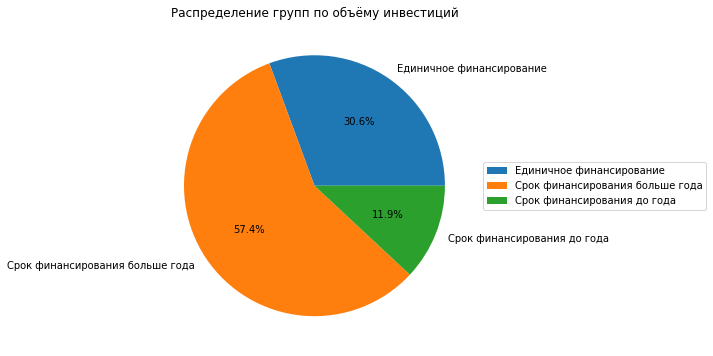

In [33]:
(df.groupby('group')['funding_total_usd'].sum()/df['funding_total_usd'].sum()).plot(kind='pie',
                                                                                 figsize=(10,6),
                                                                                 legend=True,
                                                                                 rot=0,
                                                                                 autopct='%.1f%%',
                                                                                 title='Распределение групп по объёму инвестиций',
                                                                                 ylabel='')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

По объёму привлеченных инвестиций от общего объёма на первом месте находится группа, в которой срок финансирования больше года

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесем к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесем к средним, а сегменты до 35 компаний отнесем к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.


In [34]:
market_counts=df['market'].value_counts()
market_counts

software                 4812
biotechnology            3590
mobile                   2344
e-commerce               1866
curated web              1693
                         ... 
visualization               1
space travel                1
mobile devices              1
application platforms       1
fraud detection             1
Name: market, Length: 394, dtype: int64

In [35]:
def count_market(x):
    if pd.isna(x):
        return 'Неизвестно'
    count = market_counts[x]
    if count>120:
        return 'Массовый'
    elif count>35:
        return 'Средний'
    else:
        return 'Нишевый'
df['category_market']=df['market'].apply(count_market)
counts=df.groupby('category_market')['market'].count()
shares=counts/counts.sum()
shares.sort_values()

category_market
Неизвестно    0.000000
Нишевый       0.021612
Средний       0.100016
Массовый      0.878372
Name: market, dtype: float64

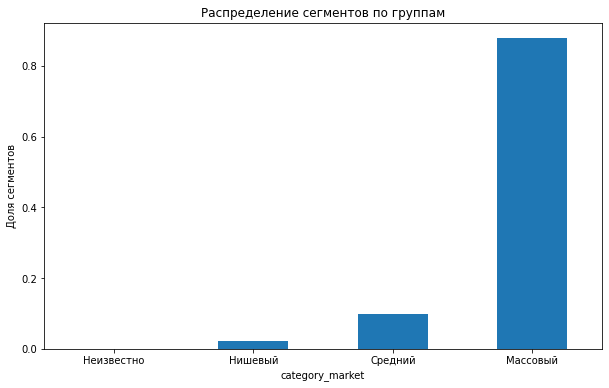

In [36]:
shares.sort_values().plot(kind='bar',
                                            figsize=(10,6),
                                            rot=0,
                                            title='Распределение сегментов по группам',
                                            ylabel='Доля сегментов')
plt.show()

Наибольшая доля сегментов относятся к категории "массовый" - 0.8

In [37]:
count_name=df.groupby('category_market')['name'].count()
shares_name=count_name/count_name.sum()
shares_name

category_market
Массовый      0.824622
Неизвестно    0.061189
Нишевый       0.020290
Средний       0.093898
Name: name, dtype: float64

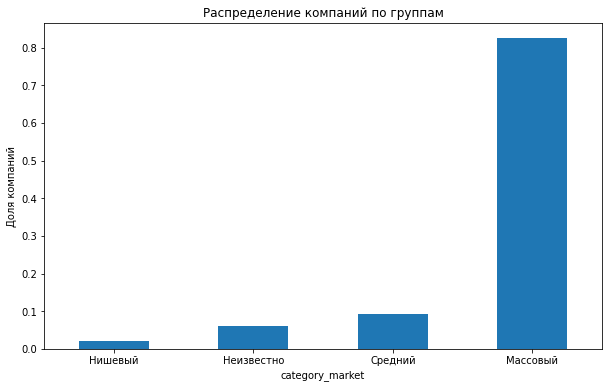

In [38]:
shares_name.sort_values().plot(kind='bar',
                                            figsize=(10,6),
                                            rot=0,
                                            title='Распределение компаний по группам',
                                            ylabel='Доля компаний')
plt.show()

Больше всего компаний также относятся к Массовому сегменту, их доля составляет 0.8

Соотвественно, рынок стартапов относится больше к Массовой категории. В этой категории находится большее количество отраслей рынка и большее количество самих компаний.


Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.



In [39]:
def finish_market(row):
    category=row['category_market']
    if category=='Массовый':
        return row['market']
    elif category=='Нишевый':
        return 'niche'
    elif pd.isna(category):
        return 'Неизвестно'
    else:
        return 'mid'
df['market']=df.apply(finish_market,axis=1)
df

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_B,round_C,round_D,round_E,round_F,round_G,round_H,funding_at,group,category_market
0,Harvard University,http://harvard.edu,|Education|,education,90000000.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Массовый
1,University of New Brunswick,http://www.unb.ca,NaN,mid,2000000.0,operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Неизвестно
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Средний
3,University of Michigan,http://www.umich.edu/,|Education|,education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Срок финансирования до года,Массовый
4,Case Western Reserve University,http://www.case.edu,|Education|,education,540000.0,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Массовый
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49433,RiverSilica,http://riversilica.com,NaN,mid,1500000.0,operating,IND,NaN,Bangalore,Bangalore,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Неизвестно
49434,SouthGobi Resources,http://southgobi.com,|Mining Technologies|,niche,9000000.0,operating,CAN,BC,Vancouver,Vancouver,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Нишевый
49435,DigiByte,http://digibyte.co,NaN,mid,250000.0,operating,USA,CA,Los Angeles,Santa Monica,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Неизвестно
49436,Xeltis,http://xeltis.com,NaN,mid,34000000.0,operating,CHE,NaN,Zurich,Zürich,...,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,True,Единичное финансирование,Неизвестно


In [40]:
df['market'].value_counts()

mid                     6344
software                4812
biotechnology           3590
mobile                  2344
e-commerce              1866
curated web             1693
enterprise software     1381
health care             1185
clean technology        1180
games                   1117
advertising             1107
hardware + software     1062
social media            1003
health and wellness      873
education                844
niche                    830
finance                  828
analytics                667
manufacturing            596
security                 567
semiconductors           484
web hosting              424
consulting               349
hospitality              336
travel                   330
fashion                  303
news                     301
messaging                295
search                   291
real estate              279
saas                     272
music                    264
internet                 241
technology               238
apps          

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

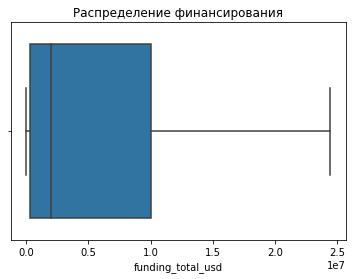

In [41]:
sns.boxplot(data=df,x='funding_total_usd',showfliers=False)
plt.title('Распределение финансирования')
plt.show()

Типичные значения финансирования находятс в пределах от 0 до 2.5 млн долларов. Финансирование более 2.5 млн долларов уже можно считать выбивающимся.

In [42]:
# Создаем столбец для выбросов
df['is_outlier'] = False

# Список всех групп
groups = df['market'].unique()

# Для каждой группы считаем IQR
for group in groups:
    # Данные группы
    group_data = df[df['market'] == group]['funding_total_usd']
    
    
    # Считаем квартили
    Q1 = group_data.quantile(0.25)
    Q3 = group_data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Границы
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Находим выбросы
    mask = (df['market'] == group) & ((df['funding_total_usd'] < lower) | (df['funding_total_usd'] > upper))
    df.loc[mask, 'is_outlier'] = True

In [43]:
result = df.groupby('market').agg(
    total=('is_outlier', 'count'),
    outliers=('is_outlier', 'sum')
)
result['percent'] = (result['outliers'] / result['total'] * 100).round(1)
result = result.sort_values('percent', ascending=False)

result

,total,outliers,percent
market,,,
real estate,279,48,17.2
entertainment,150,25,16.7
consulting,349,58,16.6
search,291,48,16.5
cloud computing,152,25,16.4
saas,272,44,16.2
photography,204,33,16.2
video,188,30,16.0
technology,238,38,16.0


Самый большое количество выбросов наблюдается в сегментe `real estate`. Процент вбросов в этом сегменте составляется 17.2

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [44]:
df['year'] = pd.to_datetime(df['first_funding_at']).dt.year
df['month'] = pd.to_datetime(df['first_funding_at']).dt.month
pivot = df.groupby(['year', 'month']).size().unstack(fill_value=0)
pivot

month,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0
year,,,,,,,,,,,,
1921.0,0,0,0,0,0,0,0,0,1,0,0,0
1960.0,1,0,0,0,0,0,0,0,0,0,1,0
1979.0,1,0,0,0,0,0,0,0,0,0,0,0
1982.0,0,0,0,0,0,1,0,0,0,0,0,2
1983.0,0,0,0,0,0,1,0,0,0,0,0,0
1984.0,1,0,0,0,0,0,0,0,0,0,0,0
1985.0,0,0,0,0,2,1,0,0,1,0,0,0
1987.0,1,0,0,0,0,0,0,0,0,0,1,0
1989.0,1,0,0,0,0,0,0,0,0,0,0,0


Данные за декабрь 2014 года скорее всего не полные, всего 23 записи.

In [45]:
#Исключаем выбросы
df_clean = df[~df['is_outlier']].copy()

In [46]:
# Извлекаем год
df_clean['year'] = pd.to_datetime(df_clean['mid_funding_at']).dt.year

In [47]:
#  Находим годы с 50+ раундами
yearly_rounds = df_clean.groupby('year')['funding_rounds'].sum()
years_with_50 = yearly_rounds[yearly_rounds >= 50].index

#  Фильтруем
df_final = df_clean[df_clean['year'].isin(years_with_50)].copy()
df_final.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 35585 entries, 1 to 49437
Data columns (total 46 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  35584 non-null  object        
 1   homepage_url          33476 non-null  object        
 2   category_list         33292 non-null  object        
 3   market                35585 non-null  object        
 4   funding_total_usd     35585 non-null  float64       
 5   status                34606 non-null  object        
 6   country_code          32026 non-null  object        
 7   state_code            21821 non-null  object        
 8   region                32026 non-null  object        
 9   city                  31422 non-null  object        
 10  funding_rounds        35585 non-null  float64       
 11  participants          23190 non-null  float64       
 12  founded_at            27731 non-null  object        
 13  founded_month   

В нашем отфильтрованном датасете осталось 35585 строк.

### 3.3. Анализ типов финансирования по объёму и популярности

Построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируемся на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.


In [48]:
existing_types=[ 'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
    'convertible_note', 'debt_financing', 'angel', 'grant', 
    'private_equity', 'post_ipo_equity', 'post_ipo_debt', 
    'secondary_market', 'product_crowdfunding']
funding_sums = df_final[existing_types].sum().sort_values(ascending=False)
funding_sums

venture                 1.278222e+11
seed                    9.409922e+09
debt_financing          8.196130e+09
private_equity          4.865932e+09
angel                   2.466486e+09
undisclosed             2.089930e+09
grant                   2.027746e+09
post_ipo_equity         1.886238e+09
convertible_note        5.592394e+08
post_ipo_debt           2.867183e+08
equity_crowdfunding     2.294788e+08
product_crowdfunding    1.779103e+08
secondary_market        3.278580e+07
dtype: float64

<AxesSubplot:>

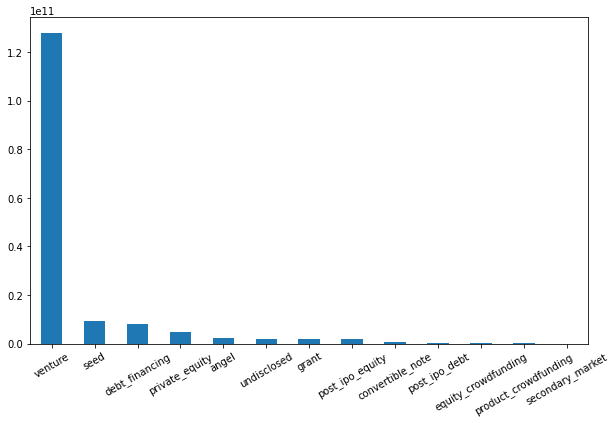

In [49]:
funding_sums.plot(kind='bar',figsize=(10,6),rot=30)

Наибольшое финансирование получил тип `venture`. Меньше всего `equity_crowdfunding `

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [50]:
funding_count = df_final[existing_types].astype(bool).sum().sort_values(ascending=False)
funding_count

venture                 18792
seed                    13358
debt_financing           3259
angel                    2929
grant                    1009
undisclosed               819
private_equity            638
convertible_note          519
equity_crowdfunding       514
product_crowdfunding      203
post_ipo_equity           161
post_ipo_debt              27
secondary_market            6
dtype: int64

<AxesSubplot:>

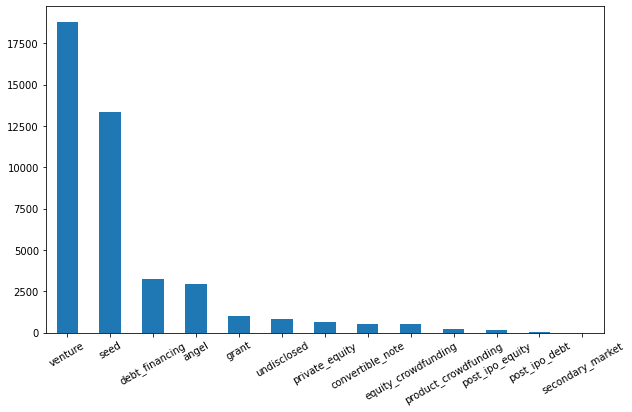

In [51]:
funding_count.plot(kind='bar',figsize=(10,6),rot=30)

По общему объёму возвратов на первом месте тип `venture`, но здесь наблюдается, что тип `seed` используется довольно часто компаниями, а именно 13358.

/tmp/ipykernel_31/876844843.py:6: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax1.set_xticklabels(funding_count.index, rotation=45)


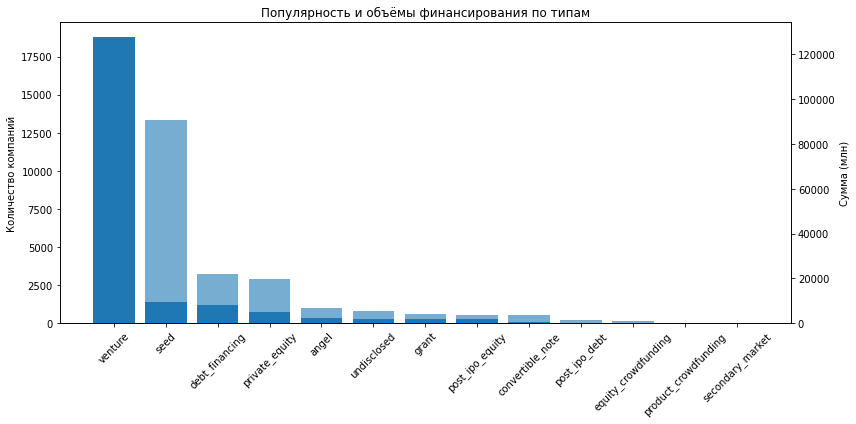

In [52]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Популярность (количество компаний)
ax1.bar(funding_count.index, funding_count.values, alpha=0.6)
ax1.set_ylabel('Количество компаний')
ax1.set_xticklabels(funding_count.index, rotation=45)

# Объём финансирования (вторая ось)
ax2 = ax1.twinx()
ax2.bar(funding_sums.index, funding_sums.values / 1000000)
ax2.set_ylabel('Сумма (млн)')

plt.title('Популярность и объёмы финансирования по типам')
plt.tight_layout()
plt.show()

На графике видно различие для некоторых сегментов в их объёме финансирования и популярности. Столбец `seed` обладает небольшим финансированием, но при этом его часто выбирают компании. Возможно, в него просто вкладывают меньшие суммы, чем в венчурные инвестиции.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитаем для каждой компании средний объём одного раунда финансирования.


In [53]:
# Рассчитываем средний объём одного раунда финансирования (в млн)
df_final['avg_funding']=df_final['funding_total_usd']/df_final['funding_rounds']/1000000
df_final[['name', 'funding_total_usd', 'funding_rounds', 'avg_funding']].head()

,name,funding_total_usd,funding_rounds,avg_funding
1,University of New Brunswick,2000000.0,1.0,2.000000
2,DuPont,9000000.0,1.0,9.000000
3,University of Michigan,7700000.0,3.0,2.566667
4,Case Western Reserve University,540000.0,1.0,0.540000
7,Duke University,8700000.0,1.0,8.700000


In [54]:
df_final['year'] = pd.to_datetime(df_final['mid_funding_at']).dt.year
yearly_median = df_final.groupby('year')['avg_funding'].median().reset_index()
yearly_median.columns = ['year', 'median_round_size']
yearly_median

,year,median_round_size
0,2000,2.125000
1,2001,2.180175
2,2002,3.225000
3,2003,1.450000
4,2004,3.000000
5,2005,4.500000
6,2006,3.766667
7,2007,2.831667
8,2008,2.166667
9,2009,1.500000


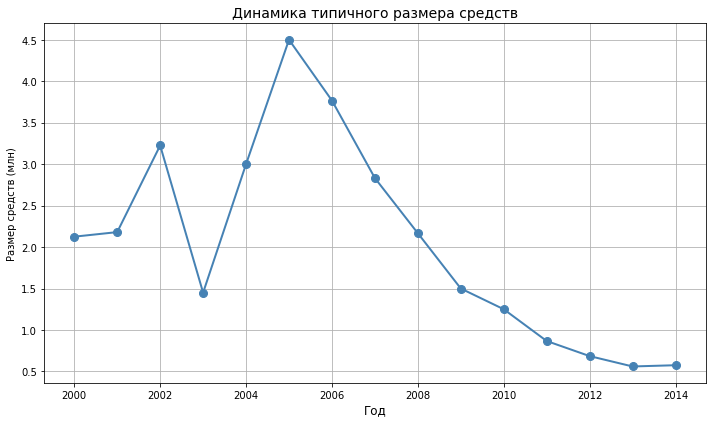

In [55]:
plt.figure(figsize=(10, 6))
plt.plot(yearly_median['year'], yearly_median['median_round_size'] ,
         marker='o', linewidth=2, color='steelblue', markersize=8)
plt.title('Динамика типичного размера средств', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Размер средств (млн)')
plt.grid(True)
plt.tight_layout()
plt.show()

На графике видно, что самое наибольшее количество привлечённых средств в среднем было в 2005 году около 4.5 млн долларов.

In [56]:
yearly_round = df_final.groupby('year')['funding_rounds'].sum().reset_index()
yearly_round

,year,funding_rounds
0,2000,110.0
1,2001,70.0
2,2002,102.0
3,2003,121.0
4,2004,178.0
5,2005,943.0
6,2006,1846.0
7,2007,2806.0
8,2008,3644.0
9,2009,4587.0


<Figure size 720x432 with 0 Axes>

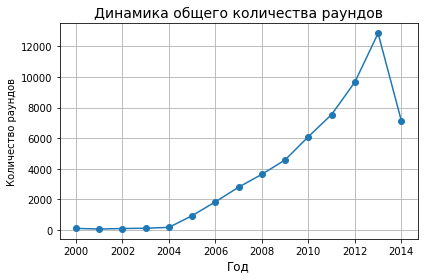

In [57]:
plt.figure(figsize=(10, 6))
yearly_round.plot(x='year', y='funding_rounds', marker='o', legend=False)
plt.title('Динамика общего количества раундов', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Количество раундов')
plt.grid(True)
plt.tight_layout()
plt.show()

По графику видно, что наибольшее количество раундов было в 2013 году - 14797 раундов. Общее количество раундов и типичный объём привлеченных средств к 2014 году уменьшилось, возможно это связано с тем, что просто данные за 2014 год не полные. Так же по этим двум графиками мы видим, что с 2005 года инвесторы стали меньше вкладывать, но при этом количество раундов финансирования увеличилось. Соотвественно, инвесторы стали вкладывать меньшие суммы в такие типы финансирования, как мы выяснили ранее, например `seed`.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберем из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.


In [58]:
pivot=df_final.pivot_table(index='year',columns='market',values='funding_total_usd',aggfunc=sum,fill_value=0)

In [59]:
if 2013 in pivot.index and 2014 in pivot.index:
    growth = pivot.loc[2014] - pivot.loc[2013]
    growing = growth[growth > 0].index.tolist()
    
    result = pivot[growing]
result

market,apps,big data,design,internet,manufacturing,medical,mid,niche,real estate,saas,startups,technology
year,,,,,,,,,,,,
2000,0,0,0,10000000,56659310,24000000,60329949,14600000,2500000,0,0,0
2001,0,0,0,0,2368582,0,32979198,24020000,0,0,0,22160000
2002,0,0,0,1100000,0,0,25106286,0,5275000,2000000,0,11000000
2003,0,0,0,0,4269608,0,17789849,0,6292200,0,0,0
2004,0,0,0,10500000,3000000,0,52236137,0,0,0,0,1750000
2005,0,0,9300000,1775000,61770000,11090000,212279786,0,250000,5240000,0,50728425
2006,1310600,0,707000,5000,163957751,20250000,284093200,11180000,2080000,4791121,0,22791000
2007,0,7780000,10800000,4495379,147726051,2100000,324629558,44494637,33220000,14652595,0,180190209
2008,4300000,2452515,5944302,23412964,173054260,28812744,463556902,22279331,46613100,27226900,5010387,277726238


Рост финансирования наблюдается в следующих сегментах: `apps`,`big data`,`design`, `internet`,`manufacturing`,`medical`,`mid`,`niche`,`real estate`,`saas`,`startups`,`technology`.
Все эти сегменты, кроме `mid`,`niche` отностя ся к Массовым.

<Figure size 1008x360 with 0 Axes>

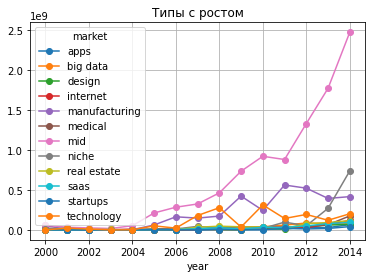

In [60]:
plt.figure(figsize=(14, 5))

result.plot(marker='o')
plt.title('Типы с ростом')
plt.grid(True)


По графику видно, что самый силдьный рост был у типа финансирований `mid`

Исключим средние и нишевые сегменты и оставим только массовые. Посмотрим, как менялся суммарный размер общего финансирования.

In [61]:
df_mass=df_final[df_final['category_market']=='Массовый'].copy()
df_mass['funding_total_usd_millions'] = df_mass['funding_total_usd']
mass_by_year=df_mass.groupby('year')['funding_total_usd'].sum()
mass_by_year

year
2000    4.076100e+08
2001    2.215914e+08
2002    3.667113e+08
2003    3.739696e+08
2004    7.320754e+08
2005    4.793913e+09
2006    8.991400e+09
2007    1.240395e+10
2008    1.499742e+10
2009    1.615393e+10
2010    1.850753e+10
2011    1.850726e+10
2012    1.884898e+10
2013    2.231082e+10
2014    1.153664e+10
Name: funding_total_usd, dtype: float64

Text(0, 0.5, 'Общий объём привлечённых инвестиций')

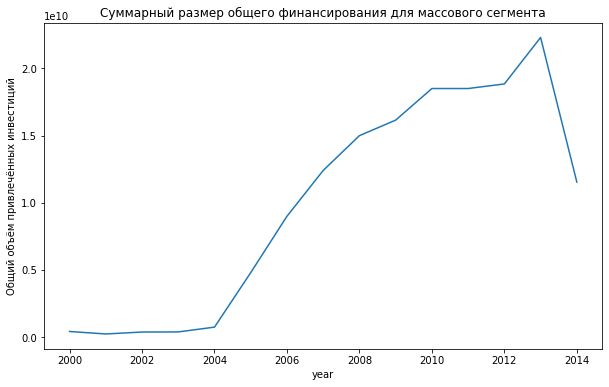

In [62]:
plt.figure(figsize=(10,6))
mass_by_year.plot(x='year',y='funding_total_usd')
plt.title('Суммарный размер общего финансирования для массового сегмента')
plt.ylabel('Общий объём привлечённых инвестиций')

Для массового сегмента наибольшее финансирование наблюдалось в 2013 году - 2,23е+10 долларов

<Figure size 1008x360 with 0 Axes>

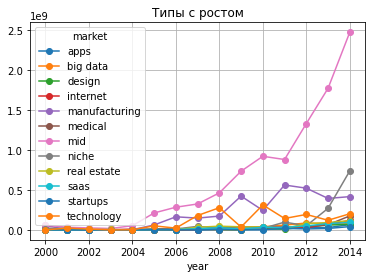

In [63]:
plt.figure(figsize=(14, 5))

result.plot(marker='o')
plt.title('Типы с ростом')
plt.grid(True)



Рост финансирования наблюдается в следующих сегментах: apps,big data,design, internet,manufacturing,medical,mid,niche,real estate,saas,startups,technology. 

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.


In [79]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
    'convertible_note', 'debt_financing', 'angel', 'grant', 
    'private_equity', 'post_ipo_equity', 'post_ipo_debt', 
    'secondary_market', 'product_crowdfunding'
]
# 1. Инвестиции
df_final['year'] = pd.to_datetime(df_final['first_funding_at']).dt.year
inv = df_final.groupby('year')[funding_types].sum()

# 2. Возвраты
ret = df_1

# 4. Доля возврата
refund = ret/ (inv + 1e-60)*1000000
for col in refund.columns:
    refund.loc[refund[col] > 2, col] = pd.NA
    refund.loc[refund[col] < 0, col] = pd.NA

refund 



,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
1985,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000,0.92,0.14,0.00,1.10,0.00,0.79,0.25,0.00,0.00,<NA>,0.00,<NA>,0.00
2001,0.26,0.07,0.00,0.75,0.01,0.30,1.82,0.00,0.00,<NA>,0.00,<NA>,0.00
2002,0.58,0.33,0.00,<NA>,<NA>,0.15,0.87,0.00,<NA>,1.13,0.00,<NA>,0.00
2003,0.36,0.29,0.00,0.61,<NA>,0.07,0.56,0.00,1.80,<NA>,0.00,<NA>,0.00


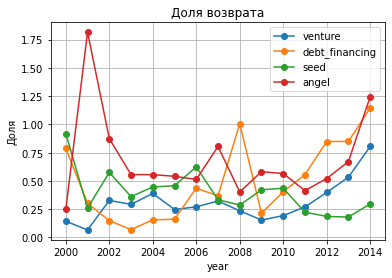

In [81]:
refund[['venture', 'debt_financing', 'private_equity','seed','angel']].plot(marker='o')
plt.title('Доля возврата')
plt.ylabel('Доля')
plt.grid(True)
plt.show()

In [66]:
# код ревьюера

 

pd.set_option('display.float_format', '{:.2f}'.format) 
refund 

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
1985,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,93999999999999996669638410630917654552868600484...,0.00,20000000000000001663832129765155154323559092938...,0.00
2001,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,46000000000000001596739378606794540790614086492...,0.00,46000000000000001596739378606794540790614086492...,0.00
2002,0.00,0.00,0.00,0.00,20000000000000001663832129765155154323559092938...,0.00,0.00,0.00,NaN,0.00,0.00,60000000000000004991496389295465462970677278814...,0.00
2003,0.00,0.00,0.00,0.00,10000000000000000831916064882577577161779546469...,0.00,0.00,0.00,0.00,21099999999999999859779555027135720780818789874...,0.00,80000000000000006655328519060620617294236371752...,0.00



## Шаг 5. Итоговый вывод и рекомендации

Во время работы над проектом было проведено разделение компаний по сегментам:Массовый, Нишевый, Средний и Неизвестно.
А также компании разделены по количеству и объему финансирования: Единичное, Финансирование меньше года и Финансирование больше года.

Наибольшое число компаний находится в группе Единичное финансирование, но наибольший объем привлеченных средств находится в группе "Срок финансирования больше года", соответсвенно надо стремиться к тому, чтобы финансирование было постоянным.
Большинство компаний находиться в массовом сегменте.

Самым популярным типом финансирования является `venture`, самым непопулярным - `equity_crowdfunding`.
В целом, в 2014 году уровень финансирования держится на высоком уровне, но стал ниже оночительно 2013.